# TP : Mixture of Experts (MoE) avec un mini-LLM en PyTorch

**Objectif.** Construire un tout petit modèle de langage (type GPT, niveau *caractère*) dont la couche feed-forward est une couche **MoE**, l'entraîner sur du **vrai texte** (Shakespeare), puis **regarder ce que fait le routeur** : quel token va vers quel expert ?

Ce TP illustre les notions vues dans la présentation :

| Notion de la présentation | Où dans le TP |
|---|---|
| Dense vs MoE : paramètres totaux vs actifs | Partie 2 |
| Routeur, Top-K, combinaison pondérée | Partie 2 (classe `MoEFFN`) |
| Switch (Top-1) vs Mixtral (Top-2) | Parties 3 et 4 |
| Équilibrage de charge : loss auxiliaire | Parties 3, 4 et 5 |
| DeepSeek-V3 : équilibrage **sans** loss auxiliaire (biais dynamique) | Parties 3, 4 et 5 |
| Capacity factor et tokens abandonnés | Partie 8 |
| Spécialisation des experts | Partie 7 |

**Comment lancer.**
- **Google Colab** (recommandé) : `Exécution > Modifier le type d'exécution > GPU`, puis `Exécution > Tout exécuter`. Internet est nécessaire pour télécharger le texte.
- **Jupyter local** : `pip install torch numpy matplotlib pandas ipywidgets`, puis lancer le notebook. Sans GPU, réduisez `CFG["steps"]` (partie 1).

**Temps d'exécution.** Les 6 entraînements prennent quelques minutes sur GPU, plus longtemps sur CPU. Pour tester vite : `CFG["steps"] = 200`.

## Partie 1 : Préparation et données réelles

On utilise **Tiny Shakespeare** (environ 1 million de caractères de pièces de théâtre). Le modèle travaille au niveau **caractère** : chaque caractère est un *token*. C'est parfait pour la visualisation, car on peut afficher chaque caractère avec la couleur de son expert.

In [1]:
!python -m pip install -ve . --no-build-isolation -Ceditable-verbose=true

Using pip 26.2.1 from c:\Users\PREDATOR HELIOS 300\miniconda3\envs\MixtureOfExperts\Lib\site-packages\pip (python 3.11)
Obtaining file:///C:/Users/PREDATOR%20HELIOS%20300/Documents/S9/MixtureOfExperts/lab


ERROR: file:///C:/Users/PREDATOR%20HELIOS%20300/Documents/S9/MixtureOfExperts/lab does not appear to be a Python project: neither 'setup.py' nor 'pyproject.toml' found.


In [2]:
import math, random, time, urllib.request
import numpy as np
!pip install --upgrade pandas --user 

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from IPython.display import HTML, display

# ---- Reproductibilité ----
SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Appareil :", device, "| PyTorch", torch.__version__)
# ---- Hyper-paramètres (modifiez ici) ----
CFG = dict(
    d_model=128,     # dimension des embeddings
    n_layers=2,      # nombre de blocs Transformer
    n_heads=4,       # têtes d'attention
    d_hidden=128,    # taille cachée d'UN expert
    n_experts=8,     # nombre d'experts par couche MoE
    block=64,        # longueur de contexte (en caractères)
    batch=64,        # taille de batch
    steps=800,       # pas d'entraînement (réduire à 200 pour tester vite)
    lr=3e-3,         # learning rate
    alpha=0.01,      # coefficient de la loss auxiliaire (Switch Transformer : 1e-2)
    bias_lr=0.01,    # vitesse de mise à jour du biais (stratégie DeepSeek)
    log_every=50,    # fréquence des évaluations
    n_chars=400_000, # on garde les premiers caractères du texte (plus rapide)
)


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


Appareil : cuda | PyTorch 2.5.1


In [3]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
FALLBACK = (
    "To be, or not to be, that is the question:\n"
    "Whether 'tis nobler in the mind to suffer\n"
    "The slings and arrows of outrageous fortune,\n"
    "Or to take arms against a sea of troubles\n"
    "And by opposing end them.\n\n"
    "ROMEO:\nBut, soft! what light through yonder window breaks?\n"
    "It is the east, and Juliet is the sun.\n\n"
    "JULIET:\nO Romeo, Romeo! wherefore art thou Romeo?\n"
    "Deny thy father and refuse thy name.\n\n"
)
try:
    text = urllib.request.urlopen(URL, timeout=20).read().decode("utf-8")
    print("Texte téléchargé.")
except Exception as e:
    print("Téléchargement impossible (", e, ") -> texte de secours très court, résultats peu intéressants.")
    text = FALLBACK * 300

text = text[:CFG["n_chars"]]
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s if c in stoi]
decode = lambda ids: "".join(itos[int(i)] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)
n_train = int(0.9 * len(data))
train_data, val_data = data[:n_train], data[n_train:]

print(f"{len(text):,} caractères | vocabulaire : {vocab_size} caractères")
print(f"train : {len(train_data):,} | validation : {len(val_data):,}")
print("\n--- Extrait ---\n" + text[:250])

Texte téléchargé.
400,000 caractères | vocabulaire : 63 caractères
train : 360,000 | validation : 40,000

--- Extrait ---
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



## Partie 2 : La couche MoE et le mini-LLM

Un bloc Transformer standard fait : `x = x + Attention(LN(x))` puis `x = x + FFN(LN(x))`.

**Dans un MoE, on remplace le FFN par plusieurs experts (des petits MLP) et un routeur.** Pour chaque token :

1. Le routeur calcule un score par expert : `logits = Linear(x)` puis `probs = softmax(logits)`.
2. On garde les **Top-K** experts (K = 1 comme Switch, K = 2 comme Mixtral).
3. On renormalise les poids des K experts choisis pour qu'ils somment à 1.
4. Sortie du token = somme pondérée des sorties des experts choisis.

**Trois modes d'équilibrage** (paramètre `balance`) :
- `"none"` : rien. Le routeur peut s'effondrer sur quelques experts favoris.
- `"aux"` : **loss auxiliaire** du Switch Transformer : `aux = N × Σ f_i · P_i`, avec `f_i` la fraction de tokens envoyés à l'expert *i* et `P_i` la probabilité moyenne du routeur pour *i*. Elle vaut 1 si la charge est parfaitement uniforme.
- `"bias"` : **équilibrage sans loss** (DeepSeek-V3). Un biais par expert est ajouté aux scores **seulement pour choisir** les Top-K. Expert surchargé : biais diminué. Expert sous-chargé : biais augmenté. Les poids de combinaison utilisent les probabilités d'origine.

**Capacity factor** (`capacity_factor`) : si un expert reçoit plus de `(tokens × K / N_experts) × CF` assignations, les suivantes sont **abandonnées** (le token garde seulement sa connexion résiduelle).

In [4]:
class MoEFFN(nn.Module):
    # Couche MoE : N experts (MLP) + routeur linéaire + Top-K.
    def __init__(self, d_model, d_hidden, n_experts=8, k=2, balance="aux",
                 capacity_factor=None, bias_lr=0.01):
        super().__init__()
        assert balance in ("none", "aux", "bias")
        self.n_experts, self.k = n_experts, k
        self.balance, self.capacity_factor, self.bias_lr = balance, capacity_factor, bias_lr
        self.router = nn.Linear(d_model, n_experts, bias=False)
        self.experts = nn.ModuleList([
            nn.Sequential(nn.Linear(d_model, d_hidden), nn.GELU(), nn.Linear(d_hidden, d_model))
            for _ in range(n_experts)
        ])
        # Biais de routage (stratégie DeepSeek) : un buffer, PAS un paramètre appris par gradient
        self.register_buffer("route_bias", torch.zeros(n_experts))
        self.aux_loss = torch.zeros(())
        self.last = {}   # infos du dernier passage, pour les visualisations

    def _capacity_mask(self, idx, cap):
        # Pour chaque assignation (token, slot), calcule sa position dans la file de son expert.
        # On garde seulement celles dont la position < cap (premier arrivé, premier servi).
        flat = idx.reshape(-1)                              # (N*k,)
        onehot = F.one_hot(flat, self.n_experts)            # (N*k, E)
        pos = ((onehot.cumsum(0) - 1) * onehot).sum(-1)     # position dans l'expert
        return (pos < cap).reshape(idx.shape)

    def forward(self, x):
        B, T, D = x.shape
        flat = x.reshape(-1, D)                             # (N, D), N = B*T tokens
        N = flat.size(0)

        logits = self.router(flat)                          # (N, E)
        probs = F.softmax(logits, dim=-1)

        # Sélection Top-K (avec biais si mode DeepSeek)
        scores = logits + self.route_bias if self.balance == "bias" else logits
        idx = scores.topk(self.k, dim=-1).indices           # (N, k)
        w = probs.gather(1, idx)                            # poids = probabilités d'origine
        w = w / w.sum(-1, keepdim=True)                     # renormalisation

        # Capacity factor
        keep = torch.ones_like(idx, dtype=torch.bool)
        if self.capacity_factor is not None:
            cap = math.ceil(N * self.k / self.n_experts * self.capacity_factor)
            keep = self._capacity_mask(idx, cap)

        # Dispatch : chaque expert traite seulement ses tokens, puis on combine
        out = torch.zeros_like(flat)
        for e, expert in enumerate(self.experts):
            tok, slot = ((idx == e) & keep).nonzero(as_tuple=True)
            if tok.numel() > 0:
                out.index_add_(0, tok, w[tok, slot].unsqueeze(-1) * expert(flat[tok]))

        # Charge : fraction des assignations reçues par chaque expert
        counts = F.one_hot(idx, self.n_experts).sum(1).sum(0).float()   # (E,)
        frac = counts / (N * self.k)
        # Loss auxiliaire : f_i (non différentiable) x P_i (différentiable)
        self.aux_loss = self.n_experts * (frac.detach() * probs.mean(0)).sum()

        # Mise à jour du biais (DeepSeek) : surchargé -> biais baisse, sous-chargé -> biais monte
        if self.balance == "bias" and self.training:
            with torch.no_grad():
                self.route_bias += self.bias_lr * torch.sign(1.0 / self.n_experts - frac)

        self.last = dict(idx=idx.detach(), w=w.detach(), keep=keep.detach(), frac=frac.detach())
        return out.reshape(B, T, D)

### Test de cohérence de la couche

On vérifie trois choses : les formes, les poids qui somment à 1, et que notre dispatch vectorisé donne **exactement** le même résultat qu'un calcul naïf token par token. On vérifie aussi que le capacity factor est respecté.

In [5]:
def test_moe_layer():
    set_seed(0)
    layer = MoEFFN(16, 32, n_experts=4, k=2, balance="none").eval()
    x = torch.randn(2, 5, 16)
    with torch.no_grad():
        y = layer(x)
        assert y.shape == x.shape
        idx, w = layer.last["idx"], layer.last["w"]
        assert torch.allclose(w.sum(-1), torch.ones(10), atol=1e-5), "les poids doivent sommer à 1"

        flat, ref = x.reshape(-1, 16), torch.zeros(10, 16)
        for i in range(10):                      # calcul naïf token par token
            for j in range(2):
                ref[i] += w[i, j] * layer.experts[int(idx[i, j])](flat[i])
        assert torch.allclose(y.reshape(-1, 16), ref, atol=1e-5), "dispatch vectorisé != calcul naïf"

        layer.capacity_factor = 0.5              # cap = ceil(10*2/4*0.5) = 3
        layer(x)
        keep, idx = layer.last["keep"], layer.last["idx"]
        for e in range(4):
            assert ((idx == e) & keep).sum() <= 3, "capacité dépassée"
        assert (~keep).any(), "avec CF=0.5 des tokens doivent être abandonnés"
    print("OK : formes, poids, dispatch et capacity factor sont corrects.")
test_moe_layer()

OK : formes, poids, dispatch et capacity factor sont corrects.


### Le mini-LLM : Transformer décodeur avec FFN dense ou MoE

On compare un modèle **dense** (FFN classique) à des modèles **MoE**. Pour que la comparaison soit juste en calcul (FLOPs), la couche dense a une taille cachée de `2 × d_hidden` : c'est le calcul actif d'un MoE **Top-2**. Un MoE Top-1 utilise moitié moins de calcul.

In [ ]:
class Attention(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        self.h = n_heads
        self.qkv = nn.Linear(d, 3 * d, bias=False)
        self.proj = nn.Linear(d, d, bias=False)
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q, k, v = [t.view(B, T, self.h, D // self.h).transpose(1, 2) for t in (q, k, v)]
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)   # attention causale
        return self.proj(y.transpose(1, 2).reshape(B, T, D))

class DenseFFN(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, h), nn.GELU(), nn.Linear(h, d))
    def forward(self, x): return self.net(x)

class Block(nn.Module):
    def __init__(self, d, n_heads, ffn):
        super().__init__()
        self.ln1, self.attn = nn.LayerNorm(d), Attention(d, n_heads)
        self.ln2, self.ffn = nn.LayerNorm(d), ffn
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.ffn(self.ln2(x))     # le token abandonné garde ce chemin résiduel

class TinyLM(nn.Module):
    def __init__(self, vocab, cfg, kind="moe", k=2, balance="aux", capacity_factor=None):
        super().__init__()
        d = cfg["d_model"]
        self.kind, self.k, self.balance = kind, k, balance
        self.n_experts = cfg["n_experts"] if kind == "moe" else 1
        self.tok, self.pos = nn.Embedding(vocab, d), nn.Embedding(cfg["block"], d)
        def make_ffn():
            if kind == "dense":
                return DenseFFN(d, 2 * cfg["d_hidden"])           # FLOPs ~ MoE Top-2
            return MoEFFN(d, cfg["d_hidden"], cfg["n_experts"], k, balance,
                          capacity_factor, cfg["bias_lr"])
        self.blocks = nn.ModuleList([Block(d, cfg["n_heads"], make_ffn()) for _ in range(cfg["n_layers"])])
        self.ln_f, self.head = nn.LayerNorm(d), nn.Linear(d, vocab, bias=False)

    def moe_layers(self):
        return [b.ffn for b in self.blocks if isinstance(b.ffn, MoEFFN)]

    def aux_loss(self):
        ms = self.moe_layers()
        return sum(m.aux_loss for m in ms) / len(ms) if ms else torch.zeros((), device=self.tok.weight.device)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.tok(idx) + self.pos(torch.arange(T, device=idx.device))
        for b in self.blocks:
            x = b(x)
        logits = self.head(self.ln_f(x))
        loss = None if targets is None else F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

def build_model(kind="moe", k=2, balance="aux", capacity_factor=None, seed=SEED):
    set_seed(seed)
    return TinyLM(vocab_size, CFG, kind, k, balance, capacity_factor).to(device)


# active params = total params - expert params + expert params * k / n_experts where 
# expert params = sum of parameters in all experts, 
# k = number of experts selected per token, 
# n_experts = total number of experts
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    expert = sum(p.numel() for n, p in model.named_parameters() if ".experts." in n)
    active = total - expert + expert * model.k / model.n_experts if expert else total
    return total, int(active)

### Paramètres totaux vs paramètres actifs

C'est l'idée centrale de la présentation : un MoE a **beaucoup** de paramètres, mais n'en utilise qu'une **petite partie** par token.

In [ ]:
rows = []
for name, kw in [("Dense", dict(kind="dense")),
                 ("MoE Top-1", dict(kind="moe", k=1)),
                 ("MoE Top-2", dict(kind="moe", k=2))]:
    total, active = count_params(build_model(**kw))
    rows.append(dict(Modèle=name, **{"Paramètres totaux": f"{total:,}", "Paramètres actifs / token": f"{active:,}",
                                     "Actifs / totaux": f"{100*active/total:.0f}%"}))

display(pd.DataFrame(rows))
print("Mémoire : proportionnelle aux paramètres TOTAUX. Calcul : proportionnel aux paramètres ACTIFS.")

,Modèle,Paramètres totaux,Paramètres actifs / token,Actifs / totaux
0,Dense,"288,512","288,512",100%
1,MoE Top-1,"687,104","224,768",33%
2,MoE Top-2,"687,104","290,816",42%


Mémoire : proportionnelle aux paramètres TOTAUX. Calcul : proportionnel aux paramètres ACTIFS.


## Partie 3 : Entraînement

On entraîne **6 modèles** avec exactement les **mêmes batchs** (générateur aléatoire dédié) pour une comparaison équitable :

1. Dense (référence)
2. MoE Top-1, sans équilibrage
3. MoE Top-1 + loss auxiliaire
4. MoE Top-2, sans équilibrage
5. MoE Top-2 + loss auxiliaire
6. MoE Top-2 + biais dynamique (DeepSeek)

À chaque évaluation, on enregistre la **charge de chaque expert** (mesurée sur un batch de validation) pour voir comment elle évolue.

In [8]:
def get_batch(split, B, T, gen):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - T - 1, (B,), generator=gen)
    x = torch.stack([d[i:i + T] for i in ix])
    y = torch.stack([d[i + 1:i + T + 1] for i in ix])
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(model, split="val", n_batches=10, seed=123):
    was = model.training
    model.eval()
    gen = torch.Generator().manual_seed(seed)           # mêmes batchs d'évaluation à chaque fois
    losses = [model(*get_batch(split, CFG["batch"], CFG["block"], gen))[1].item() for _ in range(n_batches)]
    model.train(was)
    return float(np.mean(losses))

def train(model, name="", steps=None, seed=SEED):
    steps = steps or CFG["steps"]
    gen = torch.Generator().manual_seed(seed)           # mêmes batchs pour tous les modèles
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"])
    moes = model.moe_layers()
    hist = dict(step=[], val=[], load=[])
    use_aux = (model.kind == "moe" and model.balance == "aux")
    model.train()
    t0 = time.time()
    def log(step):
        hist["step"].append(step); hist["val"].append(estimate_loss(model))
        if moes: hist["load"].append(np.stack([m.last["frac"].cpu().numpy() for m in moes]))
    for step in range(steps):
        xb, yb = get_batch("train", CFG["batch"], CFG["block"], gen)
        _, ce = model(xb, yb)
        loss = ce + CFG["alpha"] * model.aux_loss() if use_aux else ce
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        if step % CFG["log_every"] == 0:
            log(step)
            print(f"[{name}] pas {step:4d} | train {ce.item():.3f} | val {hist['val'][-1]:.3f}")
    log(steps)
    hist["time"] = time.time() - t0
    print(f"[{name}] terminé : val = {hist['val'][-1]:.3f} en {hist['time']:.0f}s\n")
    return hist

@torch.no_grad()
def measure_load(model, n_batches=10, seed=7):
    # Charge moyenne par expert (L, E) et fraction d'assignations abandonnées, en mode évaluation.
    was = model.training
    model.eval()
    moes = model.moe_layers()
    gen = torch.Generator().manual_seed(seed)
    loads, drops = [], []
    for _ in range(n_batches):
        model(get_batch("val", CFG["batch"], CFG["block"], gen)[0])
        loads.append(np.stack([m.last["frac"].cpu().numpy() for m in moes]))
        drops.append(np.mean([1 - m.last["keep"].float().mean().item() for m in moes]))
    model.train(was)
    return np.mean(loads, axis=0), float(np.mean(drops))

def load_metrics(f):
    f = np.asarray(f); E = len(f)
    return dict(max_sur_moyenne=float(E * f.max()),          # 1.0 = parfait
                cv=float(f.std() / f.mean()),                # 0 = parfait
                entropie=float(-(f * np.log(f + 1e-12)).sum() / np.log(E)))   # 1 = parfait

In [9]:
EXPS = {
    "Dense":                   dict(kind="dense"),
    "Top-1 sans équilibrage":  dict(kind="moe", k=1, balance="none"),
    "Top-1 + loss aux":        dict(kind="moe", k=1, balance="aux"),
    "Top-2 sans équilibrage":  dict(kind="moe", k=2, balance="none"),
    "Top-2 + loss aux":        dict(kind="moe", k=2, balance="aux"),
    "Top-2 + biais (DeepSeek)": dict(kind="moe", k=2, balance="bias"),
}
results = {}
for name, kw in EXPS.items():
    model = build_model(**kw)
    hist = train(model, name)
    results[name] = dict(model=model, hist=hist)

[Dense] pas    0 | train 4.387 | val 3.995
[Dense] pas   50 | train 2.430 | val 2.489
[Dense] pas  100 | train 2.220 | val 2.290
[Dense] pas  150 | train 2.062 | val 2.151
[Dense] pas  200 | train 1.930 | val 2.043
[Dense] pas  250 | train 1.902 | val 1.970
[Dense] pas  300 | train 1.820 | val 1.904
[Dense] pas  350 | train 1.734 | val 1.865
[Dense] pas  400 | train 1.728 | val 1.811
[Dense] pas  450 | train 1.651 | val 1.776
[Dense] pas  500 | train 1.665 | val 1.753
[Dense] pas  550 | train 1.573 | val 1.733
[Dense] pas  600 | train 1.655 | val 1.722
[Dense] pas  650 | train 1.494 | val 1.692
[Dense] pas  700 | train 1.568 | val 1.684
[Dense] pas  750 | train 1.571 | val 1.671
[Dense] terminé : val = 1.656 en 18s

[Top-1 sans équilibrage] pas    0 | train 4.351 | val 3.989
[Top-1 sans équilibrage] pas   50 | train 2.456 | val 2.521
[Top-1 sans équilibrage] pas  100 | train 2.306 | val 2.381
[Top-1 sans équilibrage] pas  150 | train 2.137 | val 2.229
[Top-1 sans équilibrage] pas  200 

## Partie 4 : Qualité du modèle

On compare la **loss de validation** (plus bas = mieux). Rappel : perplexité = exp(loss).

**À interpréter avec prudence.** Le modèle est minuscule, l'entraînement est court et il y a une seule graine. De petites différences peuvent être du bruit. Pour une conclusion solide, répétez avec plusieurs graines (`SEED`).

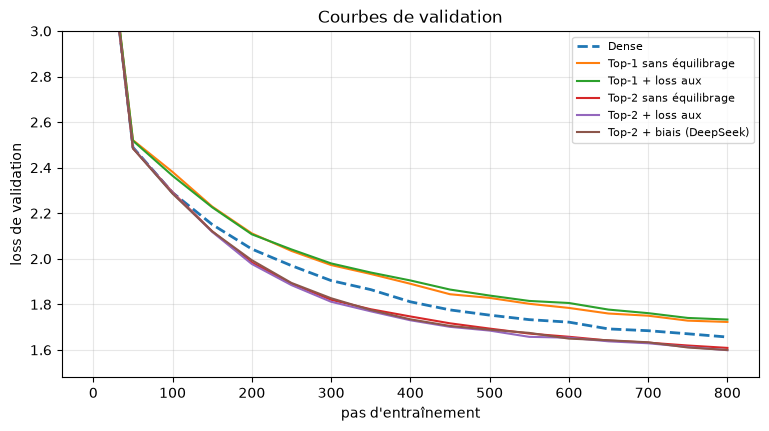

,Modèle,Loss val,Perplexité,Params actifs,Params totaux,Temps (s)
0,Top-2 + biais (DeepSeek),1.599,4.95,"290,816","687,104",33
1,Top-2 + loss aux,1.599,4.95,"290,816","687,104",28
2,Top-2 sans équilibrage,1.609,5.00,"290,816","687,104",28
3,Dense,1.656,5.24,"288,512","288,512",18
4,Top-1 sans équilibrage,1.723,5.60,"224,768","687,104",32
5,Top-1 + loss aux,1.733,5.66,"224,768","687,104",31


In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, r in results.items():
    ax.plot(r["hist"]["step"], r["hist"]["val"], label=name, lw=2 if name == "Dense" else 1.5,
            ls="--" if name == "Dense" else "-")
ax.set_xlabel("pas d'entraînement"); ax.set_ylabel("loss de validation")
ax.set_title("Courbes de validation"); ax.legend(fontsize=8); ax.grid(alpha=.3)
ax.set_ylim(top=min(3.0, ax.get_ylim()[1]))
plt.show()

rows = []
for name, r in results.items():
    total, active = count_params(r["model"])
    v = r["hist"]["val"][-1]
    rows.append({"Modèle": name, "Loss val": round(v, 3), "Perplexité": round(math.exp(v), 2),
                 "Params actifs": f"{active:,}", "Params totaux": f"{total:,}", "Temps (s)": round(r["hist"]["time"])})
display(pd.DataFrame(rows).sort_values("Loss val").reset_index(drop=True))

## Partie 5 : Charge des experts et équilibrage

Si le routage était parfaitement équilibré, chaque expert recevrait `1/8 = 12,5 %` des assignations (ligne en pointillé).

Trois métriques :
- **max / moyenne** : 1,0 = parfait. 2,0 = l'expert le plus chargé reçoit deux fois sa part.
- **CV** (coefficient de variation) : 0 = parfait.
- **Entropie normalisée** : 1 = parfait, proche de 0 = effondrement sur peu d'experts.

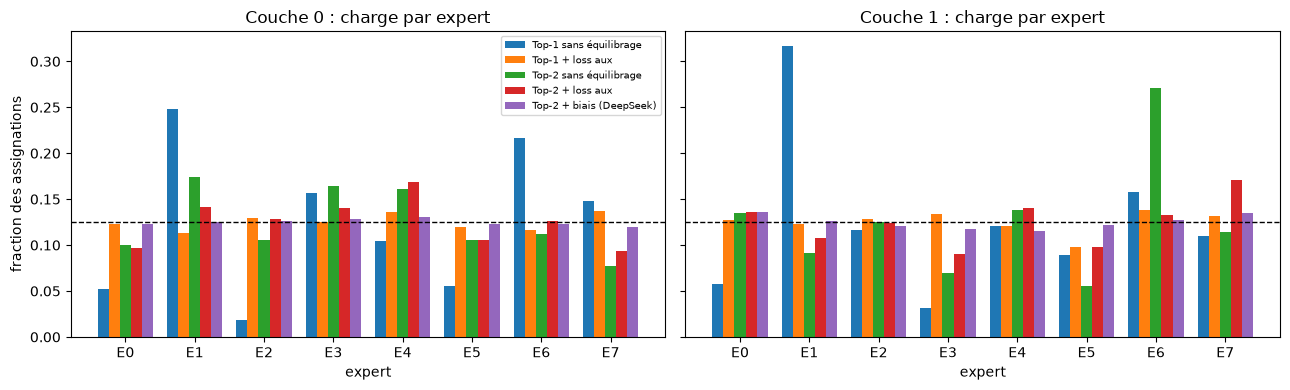

,Modèle,max / moyenne,CV,Entropie norm.
0,Top-1 sans équilibrage,2.26,0.630,0.906
1,Top-1 + loss aux,1.10,0.079,0.998
2,Top-2 sans équilibrage,1.78,0.384,0.965
3,Top-2 + loss aux,1.36,0.194,0.991
4,Top-2 + biais (DeepSeek),1.07,0.042,1.000


In [ ]:
# max / moyenne : c'est le rapport entre la charge maximale d'un expert et la charge moyenne de tous les experts
# CV : coefficient de variation = écart-type / moyenne c'est à dire la dispersion des charges autour de la moyenne
# Entropie norm. : entropie de la distribution des charges, normalisée par log(E) pour que 1 = parfait. si 8 experts reçoivent chacun environ 1/8 des tokens, l’entropie normalisée vaut près de 1. Si presque tous les tokens vont à un seul expert, elle est faible.

moe_runs = [n for n in results if results[n]["model"].kind == "moe"]
final = {n: measure_load(results[n]["model"]) for n in moe_runs}
E = CFG["n_experts"]

fig, axes = plt.subplots(1, CFG["n_layers"], figsize=(6.5 * CFG["n_layers"], 4), sharey=True)
axes = np.atleast_1d(axes)
width = 0.8 / len(moe_runs)
for L, ax in enumerate(axes):
    for i, n in enumerate(moe_runs):
        ax.bar(np.arange(E) + i * width, final[n][0][L], width, label=n)
    ax.axhline(1 / E, color="k", ls="--", lw=1)
    ax.set_title(f"Couche {L} : charge par expert"); ax.set_xlabel("expert")
    ax.set_xticks(np.arange(E) + 0.4 - width / 2); ax.set_xticklabels([f"E{e}" for e in range(E)])
axes[0].set_ylabel("fraction des assignations"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

rows = []
for n in moe_runs:
    loads, drop = final[n]
    m = [load_metrics(loads[L]) for L in range(loads.shape[0])]
    rows.append({"Modèle": n,
                 "max / moyenne": round(np.mean([x["max_sur_moyenne"] for x in m]), 2),
                 "CV": round(np.mean([x["cv"] for x in m]), 3),
                 "Entropie norm.": round(np.mean([x["entropie"] for x in m]), 3)})
display(pd.DataFrame(rows))

### Évolution de la charge pendant l'entraînement (couche 0)

Chaque courbe est un expert. Si une courbe monte vers le haut et les autres tombent vers 0, c'est un **effondrement du routeur**.

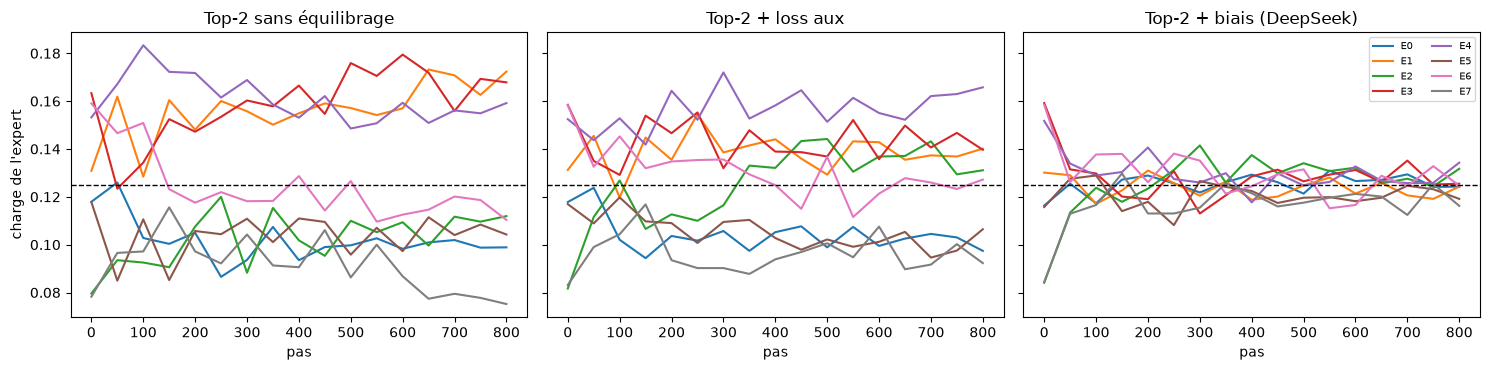

In [12]:
trio = ["Top-2 sans équilibrage", "Top-2 + loss aux", "Top-2 + biais (DeepSeek)"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, n in zip(axes, trio):
    h = results[n]["hist"]
    load = np.array(h["load"])[:, 0, :]               # (étapes, experts) pour la couche 0
    for e in range(E):
        ax.plot(h["step"], load[:, e], label=f"E{e}")
    ax.axhline(1 / E, color="k", ls="--", lw=1); ax.set_title(n); ax.set_xlabel("pas")
axes[0].set_ylabel("charge de l'expert"); axes[2].legend(ncol=2, fontsize=7)
plt.tight_layout(); plt.show()

### Questions d'interprétation (à rédiger dans le TP)

1. Dans vos résultats, la loss auxiliaire change-t-elle les métriques d'équilibre (max / moyenne, CV, entropie) ? Dans quel sens ?
2. Le mode sans équilibrage s'effondre-t-il sur quelques experts ? Si l'effet est faible, pourquoi ? (modèle petit, entraînement court, texte simple...)
3. La stratégie par biais (DeepSeek) atteint-elle un équilibre comparable à la loss auxiliaire, **sans** ajouter de terme à la loss ?
4. Un meilleur équilibre donne-t-il une meilleure loss de validation ici ? Ce résultat est-il fiable avec une seule graine ?
5. Top-1 contre Top-2 : quel est le gain de qualité, et quel est le coût en calcul ?

## Partie 6 : Voir le routage token par token

Chaque caractère est affiché avec la couleur de son **expert principal (Top-1)** en fond. Pour Top-2, le **second expert** apparaît en **souligné**. Passez la souris sur un caractère pour voir ses experts et leurs poids. Un contour **rouge** indique que le token a été abandonné par dépassement de capacité.

On utilise ici le modèle **Top-2 + loss auxiliaire**.

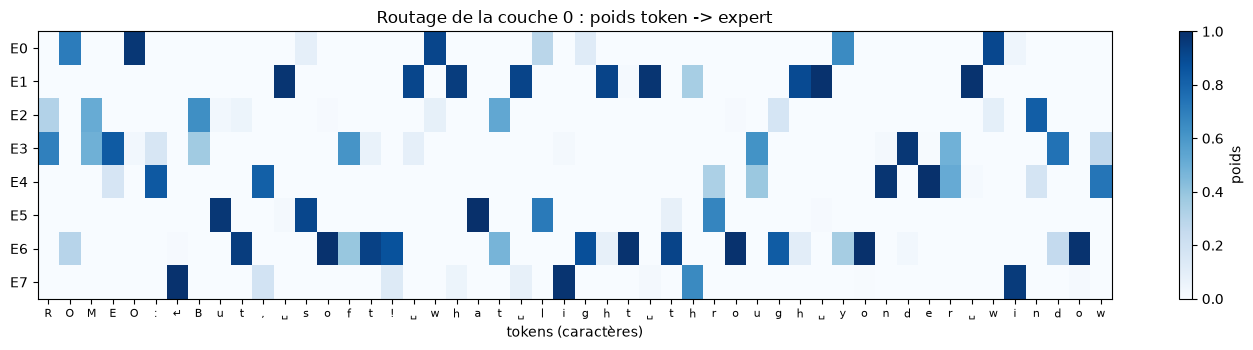

In [13]:
PALETTE = [matplotlib.colors.to_hex(plt.cm.tab10(i)) for i in range(10)]
main = results["Top-2 + loss aux"]["model"]

def lighten(hex_color, f=0.55):
    r, g, b = [int(hex_color[i:i + 2], 16) for i in (1, 3, 5)]
    return "#%02x%02x%02x" % tuple(int(c + (255 - c) * f) for c in (r, g, b))

def esc(c):
    return {"\n": "↵", "<": "&lt;", ">": "&gt;", "&": "&amp;", " ": "&nbsp;"}.get(c, c)

def legend_html(E):
    return " ".join(f'<span style="background:{lighten(PALETTE[e])};padding:2px 8px;border-radius:4px;'
                    f'font-family:monospace">E{e}</span>' for e in range(E))

@torch.no_grad()
def route_text(model, s, layer=0, cf=None, show=True):
    # Fait passer le texte dans le modèle et affiche le routage de la couche choisie.
    s = "".join(c for c in s if c in stoi)[:CFG["block"]]
    if not s:
        print("Texte vide ou caractères inconnus."); return None
    moes = model.moe_layers()
    old = [m.capacity_factor for m in moes]
    for m in moes: m.capacity_factor = cf
    was = model.training; model.eval()
    model(torch.tensor([encode(s)], device=device))
    info = {k: v.cpu().numpy() for k, v in moes[layer].last.items()}
    for m, o in zip(moes, old): m.capacity_factor = o
    model.train(was)

    idx, w, keep = info["idx"], info["w"], info["keep"]
    k = idx.shape[1]
    if show:
        spans = []
        for t, c in enumerate(s):
            tip = " | ".join(f"E{int(idx[t, j])} ({w[t, j]:.2f})" + ("" if keep[t, j] else " ABANDONNÉ") for j in range(k))
            style = f"background:{lighten(PALETTE[int(idx[t, 0])])};font-family:monospace;font-size:16px;padding:2px 0;"
            if k > 1:
                style += f"border-bottom:4px solid {PALETTE[int(idx[t, 1])]};"
            if not keep[t, 0]:
                style += "outline:2px solid red;"
            spans.append(f'<span title="{tip}" style="{style}">{esc(c)}</span>' + ("<br>" if c == "\n" else ""))
        cf_txt = "illimitée" if cf is None else cf
        head = (f"<b>Couche {layer}</b> | Top-{k} | capacity factor : {cf_txt} "
                f"| assignations abandonnées : {100 * (1 - keep.mean()):.1f}%<br>")
        display(HTML(head + legend_html(model.n_experts) +
                     "<br><div style='line-height:2;margin-top:6px'>" + "".join(spans) + "</div>"))
    return s, idx, w, keep

def plot_routing_matrix(model, s, layer=0, cf=None):
    # Matrice experts x tokens : case colorée = poids du token pour cet expert.
    out = route_text(model, s, layer, cf, show=False)
    if out is None: return
    s, idx, w, keep = out
    M = np.zeros((model.n_experts, len(s)))
    for t in range(len(s)):
        for j in range(idx.shape[1]):
            if keep[t, j]: M[idx[t, j], t] = w[t, j]
    fig, ax = plt.subplots(figsize=(max(8, len(s) * 0.28), 3.6))
    im = ax.imshow(M, aspect="auto", cmap="Blues", vmin=0, vmax=1)
    ax.set_yticks(range(model.n_experts)); ax.set_yticklabels([f"E{e}" for e in range(model.n_experts)])
    ax.set_xticks(range(len(s))); ax.set_xticklabels([{"\n": "↵", " ": "␣"}.get(c, c) for c in s], fontsize=8)
    ax.set_xlabel("tokens (caractères)"); ax.set_title(f"Routage de la couche {layer} : poids token -> expert")
    plt.colorbar(im, ax=ax, label="poids"); plt.tight_layout(); plt.show()

sample = "ROMEO:\nBut, soft! what light through yonder window"
route_text(main, sample, layer=0)
plot_routing_matrix(main, sample, layer=0)

### Version interactive

Tapez votre propre texte, changez de couche, et bougez le curseur de **capacity factor** : en bas de l'échelle, des tokens sont abandonnés (contour rouge). La valeur maximale (3,0) signifie « capacité illimitée ». *(Les widgets demandent Jupyter ou Colab.)*

In [25]:
%pip install ipywidgets

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   -------------------------------

In [ ]:

try:
    import ipywidgets as W
    def _ui(texte, couche, cf):
        route_text(main, texte, couche, None if cf >= 3.0 else cf)
    W.interact(
        _ui,
        texte=W.Textarea(value="To be, or not to be, that is the question:", continuous_update=False,
                         layout=W.Layout(width="90%", height="70px")),
        couche=W.IntSlider(min=0, max=CFG["n_layers"] - 1, step=1, value=0, description="couche"),
        cf=W.FloatSlider(min=0.25, max=3.0, step=0.25, value=3.0, description="cap. factor"),
    )
except ImportError:
    print("ipywidgets non installé : pip install ipywidgets (ou utilisez Colab). "
          "Vous pouvez quand même appeler route_text(main, 'votre texte', layer=0).")

## Partie 7 : Les experts se spécialisent-ils ?

On compte, pour chaque caractère, vers quel expert il est envoyé (sur des données de validation). Une ligne de la heatmap = la répartition d'un caractère entre les experts.

- Si une ligne est concentrée sur une colonne, le caractère va toujours au même expert (**spécialisation**).
- Si une ligne est étalée, le routage dépend peu de ce caractère.

**Attention.** Dans un modèle au niveau caractère et très petit, la spécialisation est souvent **partielle** et peut dépendre du contexte (attention) plutôt que du seul caractère. N'attendez pas un expert « voyelles » parfait.

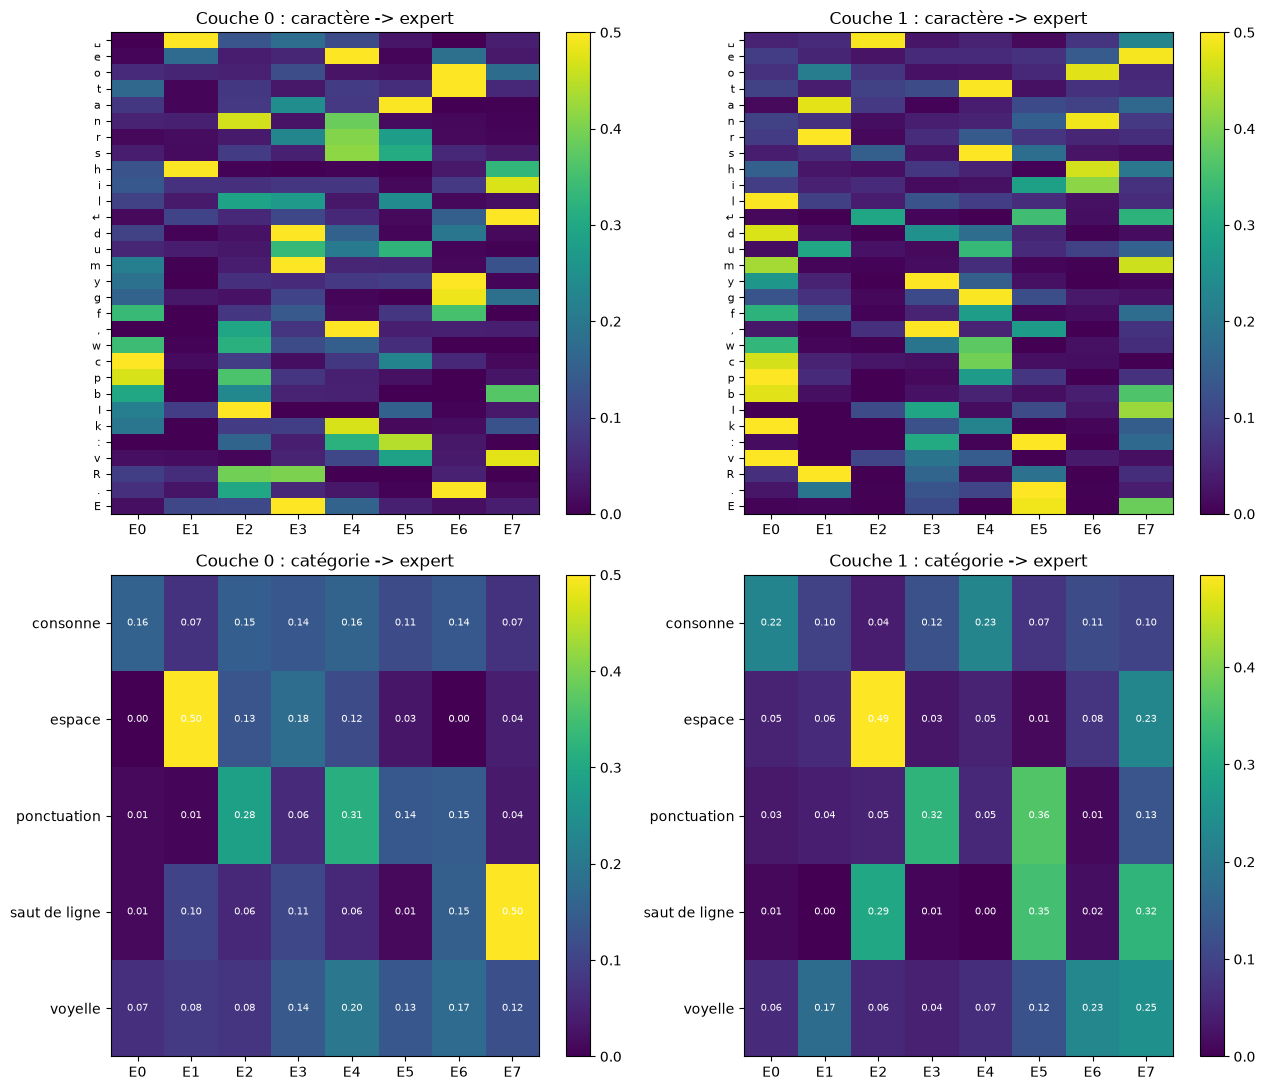

In [15]:
@torch.no_grad()
def routing_table(model, layer=0, n_batches=10, seed=11):
    was = model.training; model.eval()
    gen = torch.Generator().manual_seed(seed)
    table = np.zeros((vocab_size, model.n_experts))
    for _ in range(n_batches):
        x, _ = get_batch("val", CFG["batch"], CFG["block"], gen)
        model(x)
        idx = model.moe_layers()[layer].last["idx"].cpu().numpy()      # (B*T, k)
        ids = x.reshape(-1).cpu().numpy()
        for j in range(idx.shape[1]):
            np.add.at(table, (ids, idx[:, j]), 1)
    model.train(was)
    return table

def categorie(c):
    if c in "aeiouAEIOU": return "voyelle"
    if c.isalpha():       return "consonne"
    if c == " ":          return "espace"
    if c == "\n":         return "saut de ligne"
    if c.isdigit():       return "chiffre"
    return "ponctuation"

def label(c): return {"\n": "↵", " ": "␣"}.get(c, c)

fig, axes = plt.subplots(2, CFG["n_layers"], figsize=(6.5 * CFG["n_layers"], 11))
axes = np.array(axes).reshape(2, -1)
for L in range(CFG["n_layers"]):
    tab = routing_table(main, L)
    top = np.argsort(-tab.sum(1))[:30]                                  # 30 caractères les plus fréquents
    rows = tab[top] / tab[top].sum(1, keepdims=True)
    ax = axes[0, L]
    im = ax.imshow(rows, aspect="auto", cmap="viridis")
    ax.set_yticks(range(len(top))); ax.set_yticklabels([label(itos[i]) for i in top], fontsize=8)
    ax.set_xticks(range(main.n_experts)); ax.set_xticklabels([f"E{e}" for e in range(main.n_experts)])
    ax.set_title(f"Couche {L} : caractère -> expert"); plt.colorbar(im, ax=ax)

    cats = sorted({categorie(c) for c in chars})
    cat_tab = np.stack([sum(tab[i] for i in range(vocab_size) if categorie(itos[i]) == c) for c in cats])
    cat_tab = cat_tab / cat_tab.sum(1, keepdims=True)
    ax = axes[1, L]
    im = ax.imshow(cat_tab, aspect="auto", cmap="viridis")
    ax.set_yticks(range(len(cats))); ax.set_yticklabels(cats)
    ax.set_xticks(range(main.n_experts)); ax.set_xticklabels([f"E{e}" for e in range(main.n_experts)])
    for i in range(len(cats)):
        for j in range(main.n_experts):
            ax.text(j, i, f"{cat_tab[i, j]:.2f}", ha="center", va="center", color="w", fontsize=7)
    ax.set_title(f"Couche {L} : catégorie -> expert"); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

## Partie 8 : Capacity factor et tokens abandonnés

On reprend le modèle entraîné (sans capacity factor) et on **limite la capacité des experts à l'inférence**. Pour chaque valeur de CF on mesure la fraction d'assignations abandonnées et la loss de validation.

On s'attend à : CF petit, plus d'abandons, qualité qui baisse. CF grand, presque aucun abandon, mais plus de **padding** et de mémoire dans une vraie implémentation distribuée (ici, on ne mesure que les abandons et la loss).

,Capacity factor,Abandons (%),Loss val
0,0.50,50.000,2.490
1,0.75,25.361,1.992
2,1.00,8.059,1.702
3,1.25,1.355,1.614
4,1.50,0.000,1.599
5,2.00,0.000,1.599
6,NaN,0.000,1.599


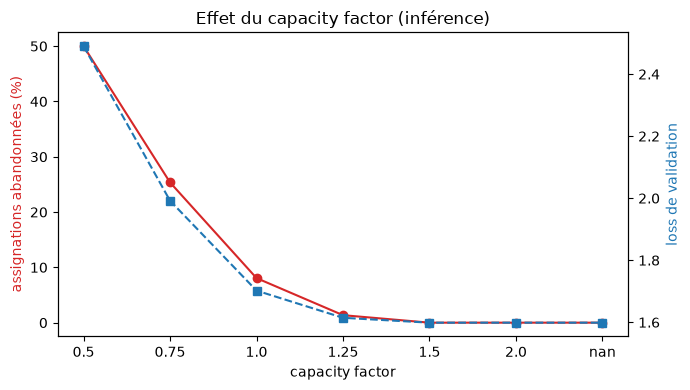

In [19]:
def set_capacity(model, cf):
    for m in model.moe_layers(): m.capacity_factor = cf

cfs = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, None]
rows = []
for cf in cfs:
    set_capacity(main, cf)
    rows.append(dict(cf=cf, drop=100 * measure_load(main)[1], val=estimate_loss(main)))
set_capacity(main, None)
df = pd.DataFrame(rows)
df["cf"] = df["cf"].apply(lambda v: "illimité" if v is None else v)
display(df.rename(columns={"cf": "Capacity factor", "drop": "Abandons (%)", "val": "Loss val"}).round(3))

fig, ax1 = plt.subplots(figsize=(7, 4))
x = np.arange(len(df))
labels = ["illimité" if v is None else str(v) for v in df["cf"]]

ax1.plot(x, df["drop"], "o-", color="tab:red")
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.set_ylabel("assignations abandonnées (%)", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(x, df["val"], "s--", color="tab:blue")
ax2.set_ylabel("loss de validation", color="tab:blue")
ax1.set_xlabel("capacity factor"); plt.title("Effet du capacity factor (inférence)"); plt.tight_layout(); plt.show()

## Partie 9 : Génération de texte avec routage

Notre mini-modèle est bien un **modèle de langage** : on peut le faire générer du texte. Avec si peu d'entraînement, le résultat ressemble à du pseudo-anglais shakespearien (des mots plausibles, mais peu de sens). C'est normal.

Ensuite on affiche le **routage des derniers caractères générés**.

In [18]:
@torch.no_grad()
def generate(model, prompt="ROMEO:\n", n_new=300, temperature=0.8, seed=0):
    was = model.training; model.eval()
    g = torch.Generator().manual_seed(seed)
    ids = torch.tensor([encode(prompt) or [0]], device=device)
    for _ in range(n_new):
        logits, _ = model(ids[:, -CFG["block"]:])
        probs = F.softmax(logits[:, -1, :] / temperature, dim=-1).cpu()
        nxt = torch.multinomial(probs, 1, generator=g).to(device)
        ids = torch.cat([ids, nxt], dim=1)
    model.train(was)
    return decode(ids[0])

generated = generate(main, "ROMEO:\n", 300)
print(generated)
print("\n--- Routage des 64 derniers caractères générés (couche 0) ---")
_ = route_text(main, generated[-CFG["block"]:], layer=0)

ROMEO:
I am undown, he the spish'd assleep, hear meet I lect men,
That call be spect their speak. Yest.

SICINIUS:
Dry, the man, my dies, and your fortune
That shat I turn your dead, which me.

First Senator:
But the majest name, adieut wreads,
And the sicklunt drople been of this lawful upon myself,
Findl

--- Routage des 64 derniers caractères générés (couche 0) ---


## Limites

- **Modèle minuscule** (2 couches, 8 experts, niveau caractère) et **entraînement court** : les phénomènes du papier (effondrement du routeur, instabilité, spécialisation fine) peuvent être faibles ou absents.
- **Une seule graine** : les petits écarts de loss sont peut-être du bruit. Pour être rigoureux, répétez sur plusieurs graines et comparez moyenne et écart-type.
- **Pas de distribution multi-GPU** : on ne mesure pas le coût de communication (all-to-all) ni le padding. Le capacity factor n'est étudié que via les tokens abandonnés.
- **Spécialisation au niveau caractère** : un caractère n'a pas de sens propre. Dans les vrais LLM (tokens de mots ou sous-mots), la spécialisation est surtout syntaxique ou thématique et reste difficile à interpréter.
- **Dense à FLOPs égaux** : la comparaison avec le dense dépend du choix de sa taille cachée.
- **Loss auxiliaire** : le coefficient `alpha` est un compromis, trop grand il dégrade la qualité (c'est la motivation de DeepSeek-V3).

## Conclusion

Nous avons construit un mini-LLM avec une couche MoE (experts MLP, routeur linéaire, Top-K, combinaison pondérée) et observé :

1. **Dense vs MoE** : beaucoup plus de paramètres totaux pour un calcul actif comparable.
2. **Routage** : on peut visualiser précisément quel caractère va vers quel expert, avec quel poids.
3. **Équilibrage** : on peut mesurer la charge des experts et comparer *aucun équilibrage*, *loss auxiliaire* (Switch) et *biais dynamique* (DeepSeek-V3).
4. **Capacity factor** : plus il est petit, plus des tokens sont abandonnés.

## Pour aller plus loin

- Remplacer les caractères par un tokenizer BPE et un corpus plus grand.
- Ajouter un **expert partagé** (comme DeepSeek-V3) et des experts plus fins.
- Ajouter une **router z-loss** et un routeur en float32 pour étudier la stabilité.
- Ajouter du **bruit sur le routeur** (noisy Top-K, input jitter) et comparer.
- Entraîner avec `capacity_factor` pendant l'entraînement (pas seulement à l'inférence).
- Répéter avec 3 à 5 graines et tracer des barres d'erreur.